In [3]:
import numpy as np

# 目标函数（与 TikZ 图同款，角度制）
def f(x):
    return (1.2*np.sin(np.deg2rad(120*x))
            + 0.6*np.cos(np.deg2rad(300*x))
            + 0.2*x + 1)

xs = np.linspace(0, 6, 2000)
ys = f(xs)

def sigmoid_fit(K):
    """K 段 Sigmoid 基函数的最小二乘拟合，返回 (绘制曲线的x, 绘制曲线的y, 节点x, 节点y)"""
    knots = np.linspace(0, 6, K+1)
    inner = knots[1:-1] # Sigmoid 的中心点
    
    # Sigmoid 的陡峭程度（权重）。这里让它与 K 成正比，使得节点越密时激活函数越陡峭，从而起到类似局部基函数的作用
    w = 3.0 * K 
    
    def sigmoid(x, t):
        # 使用 np.clip 限制指数范围，防止 np.exp 溢出警告
        return 1.0 / (1.0 + np.exp(np.clip(-w * (x - t), -500, 500)))
    
    # 构造设计矩阵 (偏置, 线性项, Sigmoid 激活项)
    A = np.column_stack([np.ones_like(xs), xs]
                        + [sigmoid(xs, t) for t in inner])
    c, *_ = np.linalg.lstsq(A, ys, rcond=None)          # ← 真·训练
    
    # 1. 生成用于平滑绘制曲线的密集点（200个点，因为 Sigmoid 是非线性平滑的）
    x_plot = np.linspace(0, 6, 200)
    A_plot = np.column_stack([np.ones_like(x_plot), x_plot]
                             + [sigmoid(x_plot, t) for t in inner])
    y_plot = A_plot @ c
    
    # 2. 生成仅在节点处的值（用于画 TikZ 里的红点和虚线）
    A_knots = np.column_stack([np.ones_like(knots), knots]
                              + [sigmoid(knots, t) for t in inner])
    y_knots = A_knots @ c
    
    return x_plot, y_plot, knots, y_knots

# 分别计算欠拟合与万能逼近
x_pF, y_pF, kF, y_kF = sigmoid_fit(8)      # 欠拟合：8 段区域
x_pM, y_pM, kM, y_kM = sigmoid_fit(36)     # 万能逼近：36 段区域

# 连线坐标 (使用密集点生成平滑曲线)
few  = " ".join(f"({x:.2f},{y:.2f})" for x, y in zip(x_pF, y_pF))
many = " ".join(f"({x:.2f},{y:.2f})" for x, y in zip(x_pM, y_pM))

# 散点坐标 (保留原本节点处画点和虚线的逻辑)
dotsF = "\n    ".join(
    f"\\fill[myred] ({x:.2f},{y:.2f}) circle (2pt);"
    f" \\draw[gray, dashed, line width=0.5pt] ({x:.2f},0) -- ({x:.2f},{y:.2f});"
    for x, y in zip(kF, y_kF))
dotsM = "\n    ".join(
    f"\\fill[myred] ({x:.2f},{y:.2f}) circle (1.2pt);"
    for x, y in zip(kM, y_kM))

# 标签位置动态计算 (对应 x=4.5 处的 y 值向下偏移)
labF = f"(4.5,{y_kF[6]-0.7:.2f})"

TEX = r"""\documentclass[border=10pt]{standalone}
\usepackage{tikz}
\definecolor{myred}{RGB}{190,60,45}
\definecolor{myblue}{RGB}{38,84,160}
\begin{document}
\begin{tikzpicture}[>=stealth, line width=0.8pt, font=\large,
    declare function={f(\x) = 1.2*sin(\x*120) + 0.6*cos(\x*300) + 0.2*\x + 1;}]

  % ===== 左：8 个隐含神经元（欠拟合）=====
  \begin{scope}[xshift=0cm]
    \draw[->] (-0.5,0) -- (6.5,0)   node[below right] {$x$};
    \draw[->] (0,-1.0) -- (0,4.5)   node[above right] {$y$};
    \coordinate (origin) at (0,0);
    \foreach \t in {1,2,3,4} \draw (0,\t) -- ++(-0.1,0);
    \foreach \t in {1,2,3}   \node[left] at (-0.12,\t) {$\t$};
    \node[below left] at (-0.08,-0.1) {$O$};
    \draw[myblue, line width=1pt, smooth, samples=200, domain=0:6]
      plot (\x, {f(\x)});
    \node[myblue] at (1.2,{f(1.2)+0.7}) {$f(x)$};
    \draw[myred, line width=1pt] plot coordinates {@FEW@};
    \node[myred] at @LABF@ {$\hat{f}(x)$};
    @DOTSF@
    \node[font=\large\bfseries] at (3,-1.7) {Few Sigmoid Neurons};
  \end{scope}

  % ===== 右：36 个隐含神经元（万能逼近）=====
  \begin{scope}[xshift=9cm]
    \draw[->] (-0.5,0) -- (6.5,0)   node[below right] {$x$};
    \draw[->] (0,-1.0) -- (0,4.5)   node[above right] {$y$};
    \coordinate (origin) at (0,0);
    \foreach \t in {1,2,3,4} \draw (0,\t) -- ++(-0.1,0);
    \foreach \t in {1,2,3}   \node[left] at (-0.12,\t) {$\t$};
    \node[below left] at (-0.08,-0.1) {$O$};
    \draw[myblue, line width=1pt, smooth, samples=200, domain=0:6]
      plot (\x, {f(\x)});
    \draw[myred, line width=1pt] plot coordinates {@MANY@};
    @DOTSM@
    \node[font=\large\bfseries] at (3,-1.7) {Many Sigmoid Neurons};
  \end{scope}

\end{tikzpicture}
\end{document}
"""

open("sigmoid_approx_2d.tex", "w", encoding="utf-8").write(
    TEX.replace("@FEW@", few).replace("@MANY@", many)
       .replace("@DOTSF@", dotsF).replace("@DOTSM@", dotsM)
       .replace("@LABF@", labF))
print("已生成 sigmoid_approx_2d.tex")

已生成 sigmoid_approx_2d.tex


In [1]:
import numpy as np

# 目标函数（与 TikZ 图同款，角度制）
def f(x):
    return (1.2*np.sin(np.deg2rad(120*x))
            + 0.6*np.cos(np.deg2rad(300*x))
            + 0.2*x + 1)

xs = np.linspace(0, 6, 2000)
ys = f(xs)

def relu_fit(K):
    """K 段线性样条的最小二乘拟合，返回 (拐点x, 拟合y)"""
    knots = np.linspace(0, 6, K+1)
    inner = knots[1:-1]
    A = np.column_stack([np.ones_like(xs), xs]
                        + [np.maximum(0, xs-t) for t in inner])
    c, *_ = np.linalg.lstsq(A, ys, rcond=None)          # ← 真·训练
    Ak = np.column_stack([np.ones_like(knots), knots]
                         + [np.maximum(0, knots-t) for t in inner])
    return knots, Ak @ c

kF, yF = relu_fit(8)      # 欠拟合：8 个 ReLU
kM, yM = relu_fit(36)     # 万能逼近：36 个 ReLU

few  = " ".join(f"({x:.2f},{y:.2f})" for x, y in zip(kF, yF))
many = " ".join(f"({x:.2f},{y:.2f})" for x, y in zip(kM, yM))
dotsF = "\n    ".join(
    f"\\fill[myred] ({x:.2f},{y:.2f}) circle (2pt);"
    f" \\draw[gray, dashed, line width=0.5pt] ({x:.2f},0) -- ({x:.2f},{y:.2f});"
    for x, y in zip(kF, yF))
dotsM = "\n    ".join(
    f"\\fill[myred] ({x:.2f},{y:.2f}) circle (1.2pt);"
    for x, y in zip(kM, yM))
labF = f"(4.5,{yF[6]-0.7:.2f})"

TEX = r"""\documentclass[border=10pt]{standalone}
\usepackage{tikz}
\definecolor{myred}{RGB}{190,60,45}
\definecolor{myblue}{RGB}{38,84,160}
\begin{document}
\begin{tikzpicture}[>=stealth, line width=0.8pt, font=\large,
    declare function={f(\x) = 1.2*sin(\x*120) + 0.6*cos(\x*300) + 0.2*\x + 1;}]

  % ===== 左：8 段真最小二乘拟合（欠拟合）=====
  \begin{scope}[xshift=0cm]
    \draw[->] (-0.5,0) -- (6.5,0)   node[below right] {$x$};
    \draw[->] (0,-1.0) -- (0,4.5)   node[above right] {$y$};
    \coordinate (origin) at (0,0);
    \foreach \t in {1,2,3,4} \draw (0,\t) -- ++(-0.1,0);
    \foreach \t in {1,2,3}   \node[left] at (-0.12,\t) {$\t$};
    \node[below left] at (-0.08,-0.1) {$O$};
    \draw[myblue, line width=1pt, smooth, samples=200, domain=0:6]
      plot (\x, {f(\x)});
    \node[myblue] at (1.2,{f(1.2)+0.7}) {$f(x)$};
    \draw[myred, line width=1pt] plot coordinates {@FEW@};
    \node[myred] at @LABF@ {$\hat{f}(x)$};
    @DOTSF@
    \node[font=\large\bfseries] at (3,-1.7) {Few ReLU Neurons};
  \end{scope}

  % ===== 右：36 段真最小二乘拟合（万能逼近）=====
  \begin{scope}[xshift=9cm]
    \draw[->] (-0.5,0) -- (6.5,0)   node[below right] {$x$};
    \draw[->] (0,-1.0) -- (0,4.5)   node[above right] {$y$};
    \coordinate (origin) at (0,0);
    \foreach \t in {1,2,3,4} \draw (0,\t) -- ++(-0.1,0);
    \foreach \t in {1,2,3}   \node[left] at (-0.12,\t) {$\t$};
    \node[below left] at (-0.08,-0.1) {$O$};
    \draw[myblue, line width=1pt, smooth, samples=200, domain=0:6]
      plot (\x, {f(\x)});
    \draw[myred, line width=1pt] plot coordinates {@MANY@};
    @DOTSM@
    \node[font=\large\bfseries] at (3,-1.7) {Many ReLU Neurons};
  \end{scope}

\end{tikzpicture}
\end{document}
"""

open("relu_approx_2d.tex", "w").write(
    TEX.replace("@FEW@", few).replace("@MANY@", many)
       .replace("@DOTSF@", dotsF).replace("@DOTSM@", dotsM)
       .replace("@LABF@", labF))
print("已生成 relu_approx_2d.tex")

已生成 relu_approx_2d.tex


图像已保存至: ./complex_function_3d.pdf


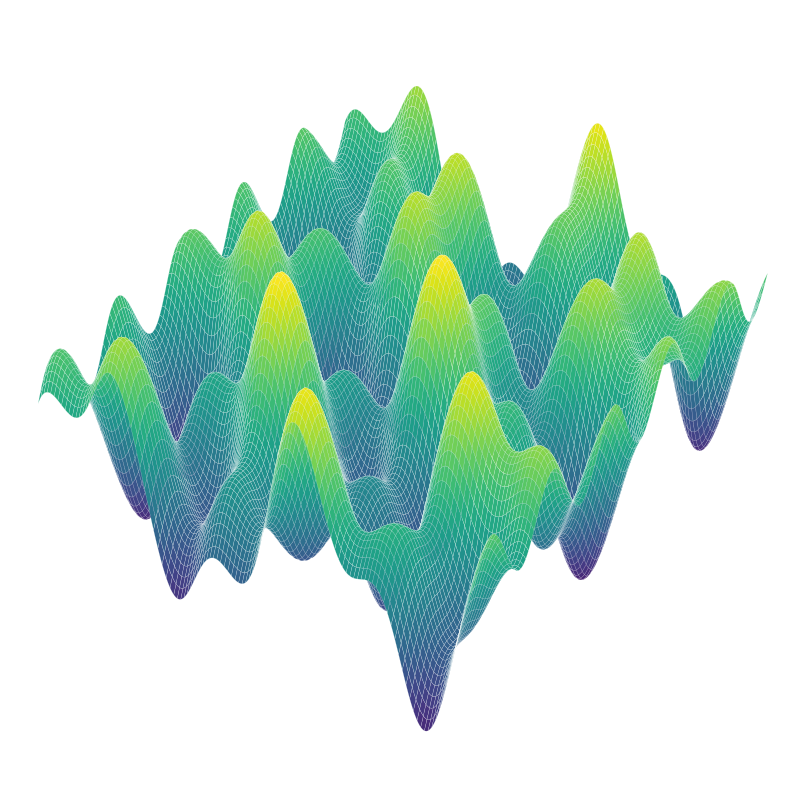

RMSE few  = 0.662
RMSE many = 0.144
图像已保存至: ./sigmoid_approx_3d.pdf


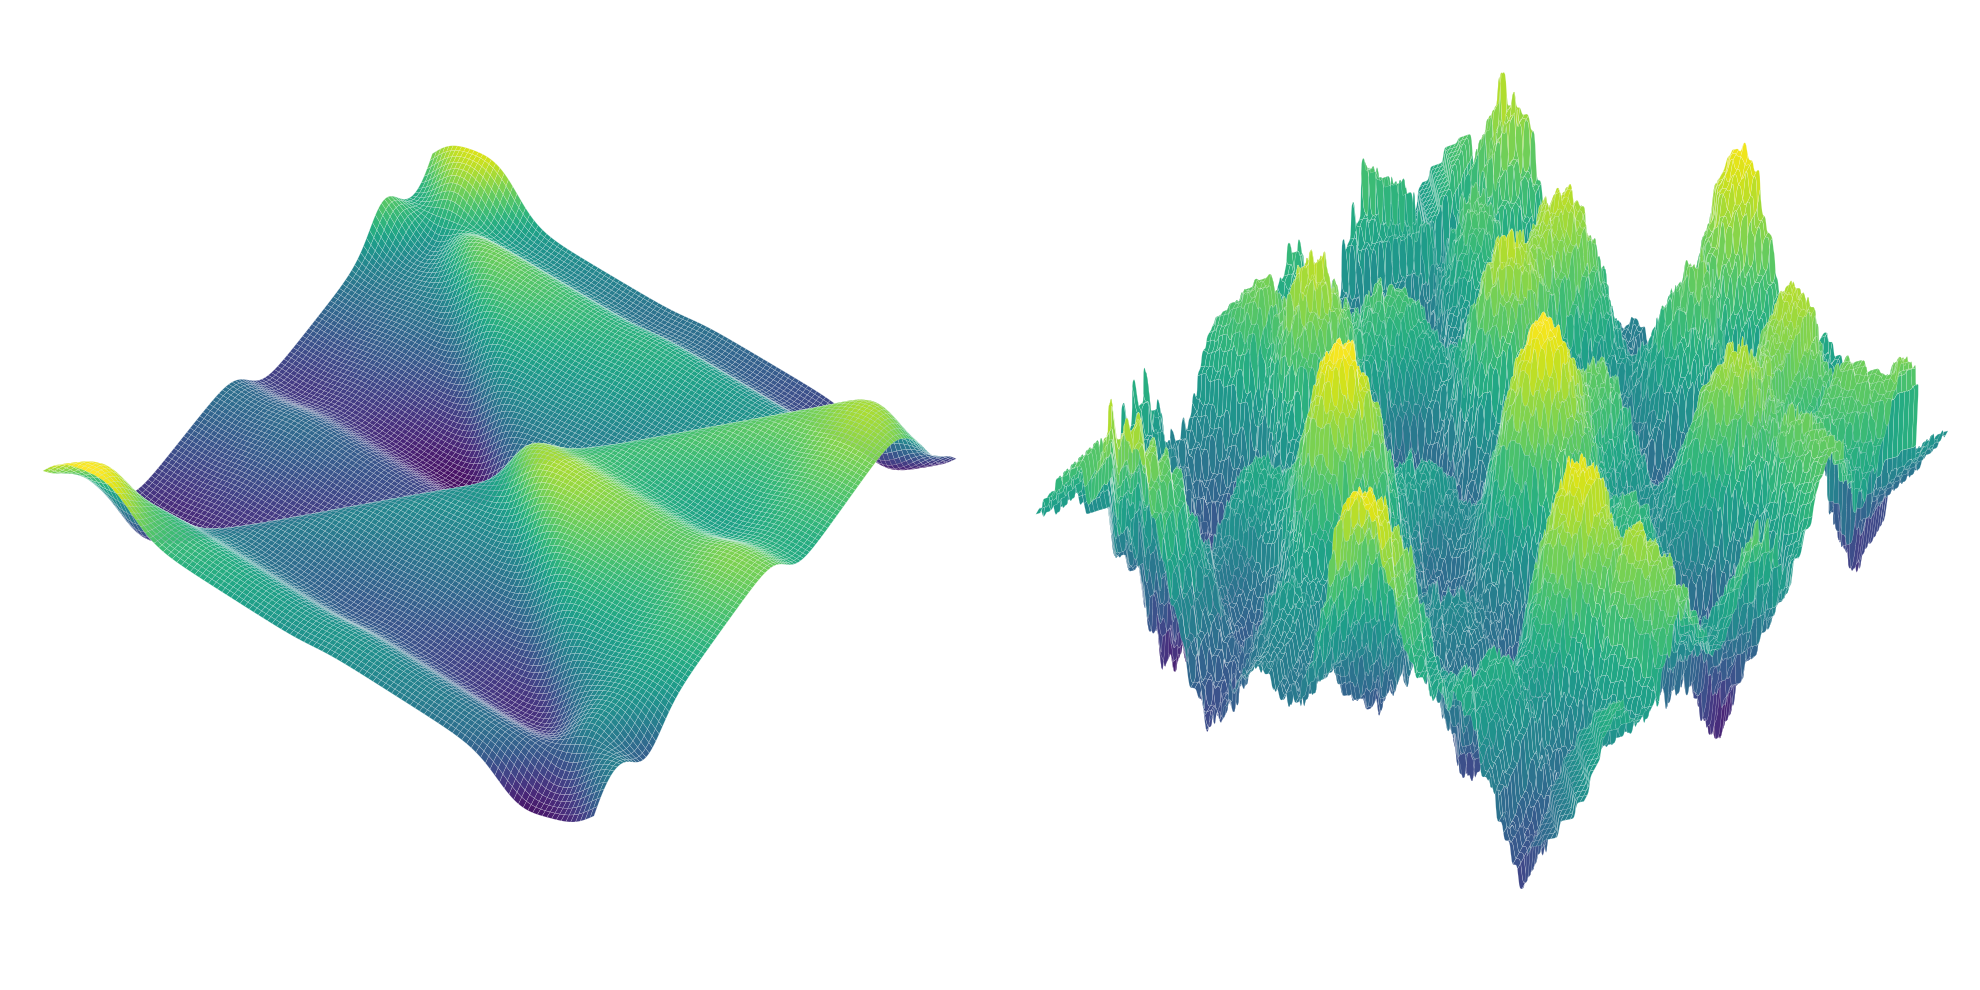

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'

def target_surface(x, y):
    """坑洼目标曲面"""
    return (1.1*np.sin(np.deg2rad(120*x))*np.cos(np.deg2rad(120*y))
            + 0.5*np.cos(np.deg2rad(300*x))
            + 0.4*np.sin(np.deg2rad(300*y))
            + 0.05*(x + y) + 1.2)

def _make_units(n_off):
    units = []
    for t in np.linspace(0.6, 5.4, n_off):
        units += [(1, 0, -t), (-1, 0, t)]
    for t in np.linspace(0.6, 5.4, n_off):
        units += [(0, 1, -t), (0, -1, t)]
    for u in np.linspace(1.0, 11.0, n_off):
        units += [(1, 1, -u), (-1, -1, u)]
    for v in np.linspace(-5.0, 5.0, n_off):
        units += [(1, -1, -v), (-1, 1, v)]
    return units

def _sigmoid2d_fit(n_off, xs, ys, zs):
    """使用 Sigmoid 作为基函数进行最小二乘拟合"""
    units = _make_units(n_off)
    
    # 陡峭度 w：基函数越多（网格越密），Sigmoid 需要越陡峭，以捕捉高频细节
    w = 2.5 * n_off 
    
    def sigmoid(val):
        # 使用 np.clip 限制范围，防止 np.exp 溢出
        return 1.0 / (1.0 + np.exp(np.clip(-w * val, -500, 500)))

    # 构造设计矩阵 A
    A = np.column_stack([np.ones_like(xs), xs, ys]
                        + [sigmoid(a*xs + b*ys + c) for a, b, c in units])
    
    # 最小二乘求解权重
    weight, *_ = np.linalg.lstsq(A, zs, rcond=None)
    
    def predict(Xg, Yg):
        xg, yg = Xg.ravel(), Yg.ravel()
        P = np.column_stack([np.ones_like(xg), xg, yg]
                            + [sigmoid(a*xg + b*yg + c) for a, b, c in units])
        return (P @ weight).reshape(Xg.shape)
    
    return predict

def _render_panel(ax, XP, YP, Zp, zlo, zhi, cmap3d, elev, azim, zoom3d):
    ax.set_facecolor('white')
    ax.plot_surface(
        XP, YP, Zp,
        cmap=cmap3d,
        edgecolor=(1.0, 1.0, 1.0, 0.45),
        linewidth=0.25,
        rcount=120, ccount=120,
        antialiased=True,
        shade=True,
    )
    ax.set_zlim(zlo, zhi)
    ax.view_init(elev=elev, azim=azim)
    ax.set_axis_off()
    ax.xaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.yaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.zaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    try:
        ax.set_box_aspect(None, zoom=zoom3d)     # ← 曲面整体放大
    except TypeError:
        ax.set_box_aspect(None)

def plot_target3d_true(
    range_xy=(0, 6),
    resolution=600,
    cmap3d='viridis',
    elev=40, azim=-55,
    zoom3d=1.2,
    output_file='./complex_function_3d.pdf',
    save=True,
    show=True,
):
    x = np.linspace(*range_xy, resolution)
    y = np.linspace(*range_xy, resolution)
    XP, YP = np.meshgrid(x, y)
    Zp = target_surface(XP, YP)

    fig = plt.figure(figsize=(10, 10), facecolor='white')
    ax = fig.add_subplot(111, projection='3d')
    _render_panel(ax, XP, YP, Zp, Zp.min()-0.2, Zp.max()+0.2,
                  cmap3d, elev, azim, zoom3d)

    if save:
        plt.savefig(output_file, format='pdf', bbox_inches='tight',
                    pad_inches=0, facecolor='white', edgecolor='none', dpi=600)
        print(f"图像已保存至: {output_file}")
    if show:
        plt.show()
    plt.close(fig)

def plot_sigmoid3d_fit(
    range_xy=(0, 6),
    resolution=600,
    n_train=50,
    n_off_few=3,
    n_off_many=60,
    cmap3d='viridis',
    elev=40, azim=-55,
    zoom3d=1.2,
    output_file='./sigmoid_approx_3d.pdf',
    save=True,
    show=True,
):
    gt = np.linspace(*range_xy, n_train)
    X, Y = np.meshgrid(gt, gt)
    Z = target_surface(X, Y)
    xs, ys, zs = X.ravel(), Y.ravel(), Z.ravel()

    fit_few  = _sigmoid2d_fit(n_off_few,  xs, ys, zs)
    fit_many = _sigmoid2d_fit(n_off_many, xs, ys, zs)
    
    print(f"RMSE few  = {np.sqrt(np.mean((fit_few(X, Y)-Z)**2)):.3f}")
    print(f"RMSE many = {np.sqrt(np.mean((fit_many(X, Y)-Z)**2)):.3f}")

    g = np.linspace(*range_xy, resolution)
    XP, YP = np.meshgrid(g, g)
    zlo, zhi = Z.min()-0.2, Z.max()+0.2

    # 大图尺寸不变，无文字，两个曲面放大吃满画面
    fig = plt.figure(figsize=(20, 10), facecolor='white')
    for i, fit in enumerate((fit_few, fit_many)):
        ax = fig.add_subplot(1, 2, i+1, projection='3d')
        _render_panel(ax, XP, YP, fit(XP, YP), zlo, zhi,
                      cmap3d, elev, azim, zoom3d)
    fig.subplots_adjust(left=0.01, right=0.99, top=1.0, bottom=0.0,
                        wspace=0.02)

    if save:
        plt.savefig(output_file, format='pdf', bbox_inches='tight',
                    pad_inches=0, facecolor='white', edgecolor='none', dpi=600)
        print(f"图像已保存至: {output_file}")
    if show:
        plt.show()
    plt.close(fig)

# 1. 绘制原曲面（目标函数），生成 complex_function_3d.pdf
plot_target3d_true(resolution=600, cmap3d='viridis',
                   output_file='./complex_function_3d.pdf')
# 2. 绘制 Sigmoid 拟合曲面，生成 sigmoid_approx_3d.pdf
plot_sigmoid3d_fit(resolution=600, cmap3d='viridis',
                   output_file='./sigmoid_approx_3d.pdf')

图像已保存至: ./complex_function_3d.pdf


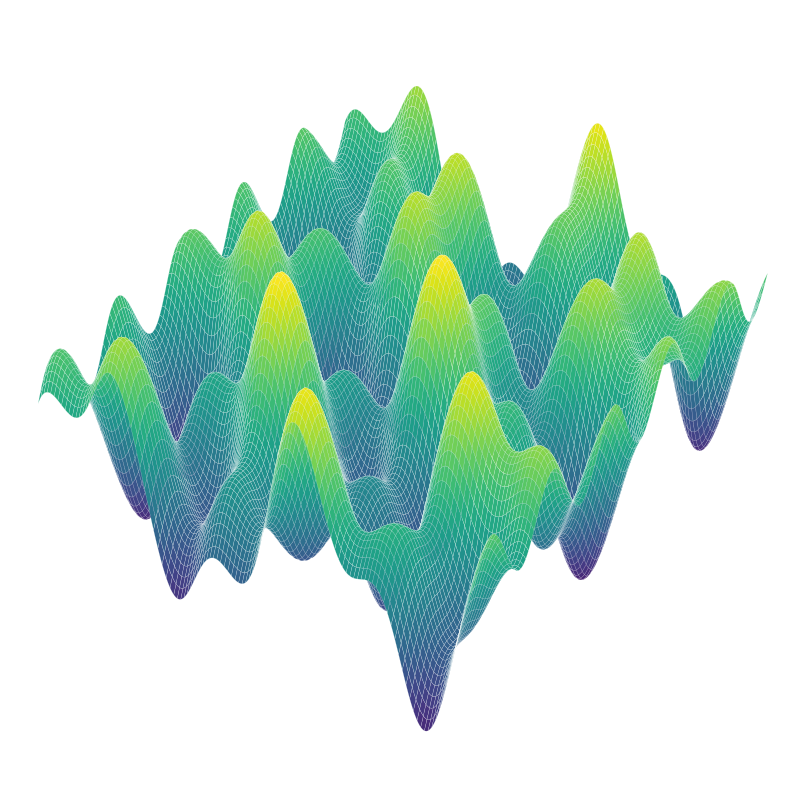

RMSE few  = 0.691
RMSE many = 0.079
图像已保存至: ./relu_approx_3d.pdf


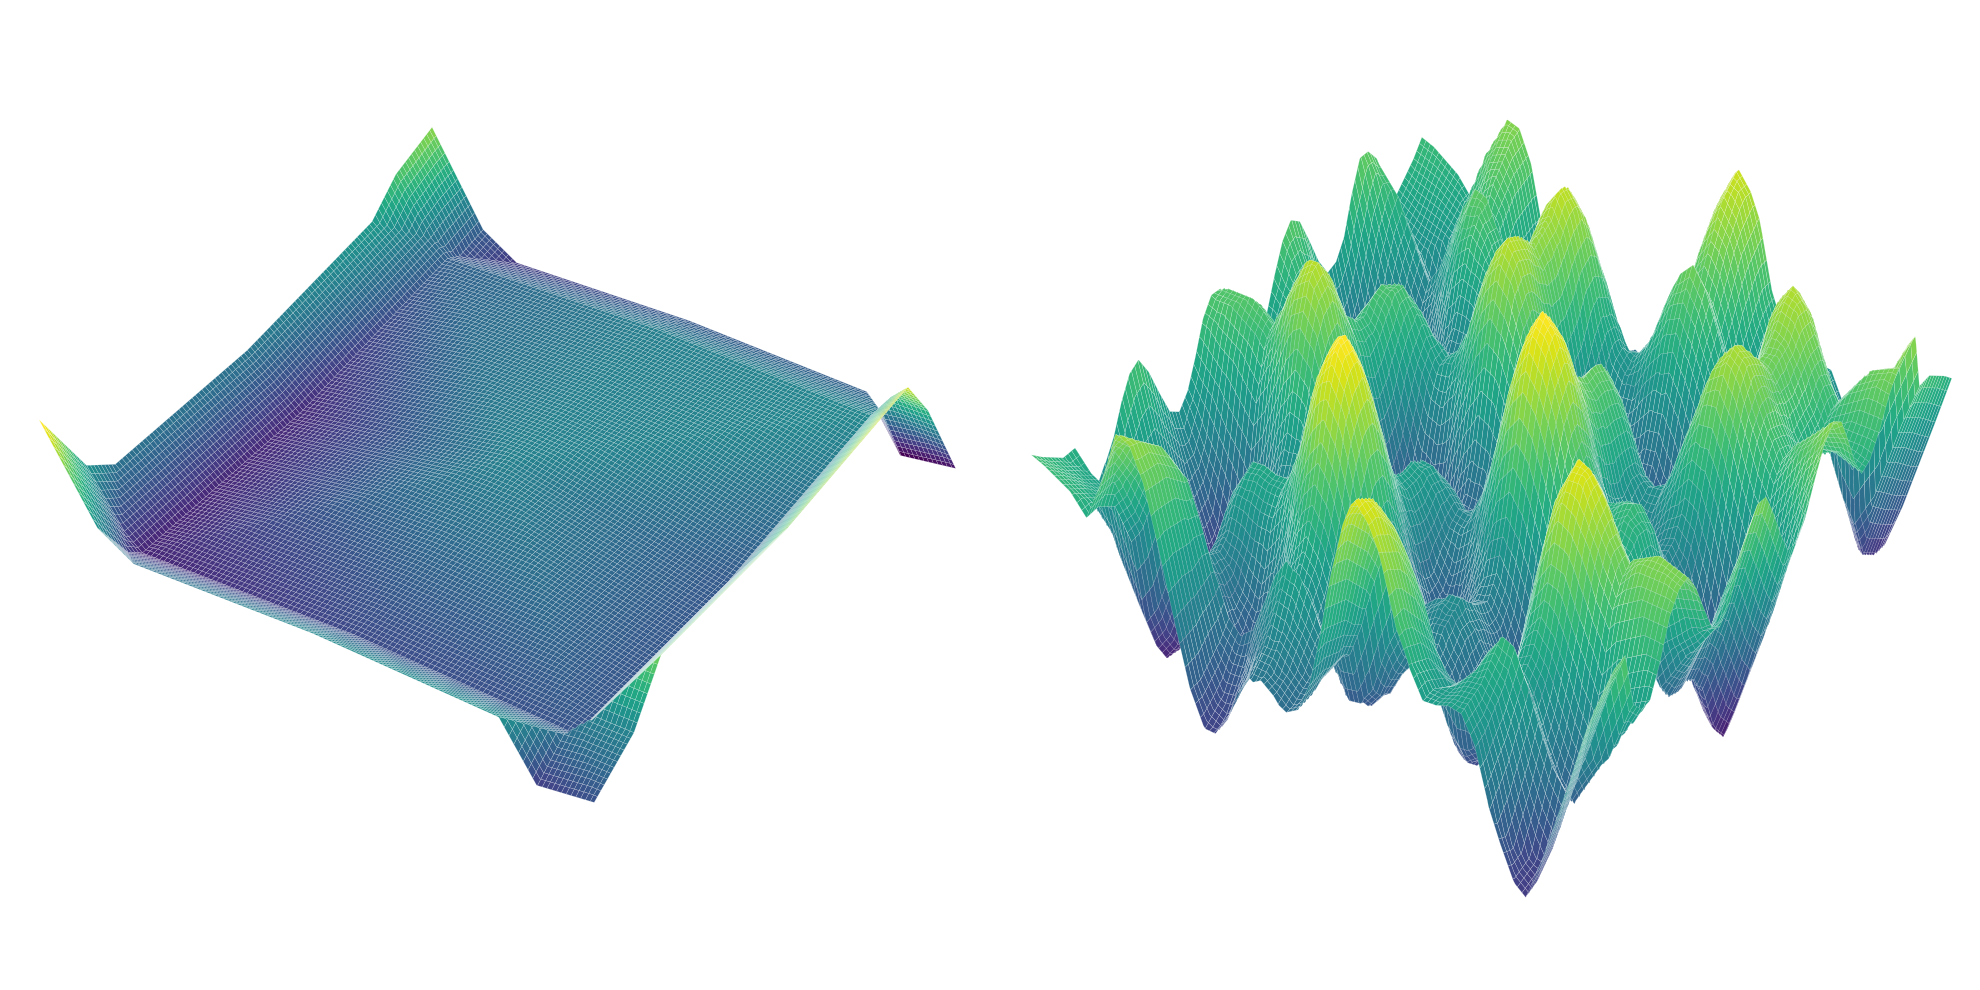

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

plt.rcParams['text.usetex'] = True
plt.rcParams['font.family'] = 'serif'

def target_surface(x, y):
    """坑洼目标曲面"""
    return (1.1*np.sin(np.deg2rad(120*x))*np.cos(np.deg2rad(120*y))
            + 0.5*np.cos(np.deg2rad(300*x))
            + 0.4*np.sin(np.deg2rad(300*y))
            + 0.05*(x + y) + 1.2)

def _make_units(n_off):
    units = []
    for t in np.linspace(0.6, 5.4, n_off):
        units += [(1, 0, -t), (-1, 0, t)]
    for t in np.linspace(0.6, 5.4, n_off):
        units += [(0, 1, -t), (0, -1, t)]
    for u in np.linspace(1.0, 11.0, n_off):
        units += [(1, 1, -u), (-1, -1, u)]
    for v in np.linspace(-5.0, 5.0, n_off):
        units += [(1, -1, -v), (-1, 1, v)]
    return units

def _relu2d_fit(n_off, xs, ys, zs):
    units = _make_units(n_off)
    A = np.column_stack([np.ones_like(xs), xs, ys]
                        + [np.maximum(0, a*xs + b*ys + c) for a, b, c in units])
    w, *_ = np.linalg.lstsq(A, zs, rcond=None)
    def predict(Xg, Yg):
        xg, yg = Xg.ravel(), Yg.ravel()
        P = np.column_stack([np.ones_like(xg), xg, yg]
                            + [np.maximum(0, a*xg + b*yg + c) for a, b, c in units])
        return (P @ w).reshape(Xg.shape)
    return predict

def _render_panel(ax, XP, YP, Zp, zlo, zhi, cmap3d, elev, azim, zoom3d):
    ax.set_facecolor('white')
    ax.plot_surface(
        XP, YP, Zp,
        cmap=cmap3d,
        edgecolor=(1.0, 1.0, 1.0, 0.45),
        linewidth=0.25,
        rcount=120, ccount=120,
        antialiased=True,
        shade=True,
    )
    ax.set_zlim(zlo, zhi)
    ax.view_init(elev=elev, azim=azim)
    ax.set_axis_off()
    ax.xaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.yaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    ax.zaxis.set_pane_color((1.0, 1.0, 1.0, 0.0))
    try:
        ax.set_box_aspect(None, zoom=zoom3d)     # ← 曲面整体放大
    except TypeError:
        ax.set_box_aspect(None)

def plot_relu3d_true(
    range_xy=(0, 6),
    resolution=600,
    cmap3d='viridis',
    elev=40, azim=-55,
    zoom3d=1.2,
    output_file='./complex_function_3d.pdf',
    save=True,
    show=True,
):
    x = np.linspace(*range_xy, resolution)
    y = np.linspace(*range_xy, resolution)
    XP, YP = np.meshgrid(x, y)
    Zp = target_surface(XP, YP)

    fig = plt.figure(figsize=(10, 10), facecolor='white')
    ax = fig.add_subplot(111, projection='3d')
    _render_panel(ax, XP, YP, Zp, Zp.min()-0.2, Zp.max()+0.2,
                  cmap3d, elev, azim, zoom3d)

    if save:
        plt.savefig(output_file, format='pdf', bbox_inches='tight',
                    pad_inches=0, facecolor='white', edgecolor='none', dpi=600)
        print(f"图像已保存至: {output_file}")
    if show:
        plt.show()
    plt.close(fig)

def plot_relu3d_fit(
    range_xy=(0, 6),
    resolution=600,
    n_train=60,
    n_off_few=3,
    n_off_many=36,
    cmap3d='viridis',
    elev=40, azim=-55,
    zoom3d=1.2,
    output_file='./relu_approx_3d.pdf',
    save=True,
    show=True,
):
    gt = np.linspace(*range_xy, n_train)
    X, Y = np.meshgrid(gt, gt)
    Z = target_surface(X, Y)
    xs, ys, zs = X.ravel(), Y.ravel(), Z.ravel()

    fit_few  = _relu2d_fit(n_off_few,  xs, ys, zs)
    fit_many = _relu2d_fit(n_off_many, xs, ys, zs)
    print(f"RMSE few  = {np.sqrt(np.mean((fit_few(X, Y)-Z)**2)):.3f}")
    print(f"RMSE many = {np.sqrt(np.mean((fit_many(X, Y)-Z)**2)):.3f}")

    g = np.linspace(*range_xy, resolution)
    XP, YP = np.meshgrid(g, g)
    zlo, zhi = Z.min()-0.2, Z.max()+0.2

    # 大图尺寸不变，无文字，两个曲面放大吃满画面
    fig = plt.figure(figsize=(20, 10), facecolor='white')
    for i, fit in enumerate((fit_few, fit_many)):
        ax = fig.add_subplot(1, 2, i+1, projection='3d')
        _render_panel(ax, XP, YP, fit(XP, YP), zlo, zhi,
                      cmap3d, elev, azim, zoom3d)
    fig.subplots_adjust(left=0.01, right=0.99, top=1.0, bottom=0.0,
                        wspace=0.02)

    if save:
        plt.savefig(output_file, format='pdf', bbox_inches='tight',
                    pad_inches=0, facecolor='white', edgecolor='none', dpi=600)
        print(f"图像已保存至: {output_file}")
    if show:
        plt.show()
    plt.close(fig)

plot_relu3d_true(resolution=600, cmap3d='viridis',
                 output_file='./complex_function_3d.pdf')
plot_relu3d_fit(resolution=600, cmap3d='viridis',
                output_file='./relu_approx_3d.pdf')